<a href="https://colab.research.google.com/github/garrettdsparks/SDP-CSE21-ME24/blob/elliston-dev/multi_stage_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 3 test image(s) in Drive.

---------------------------------------------
Processing Image: testboiler.jpg
Boiler found.
Results saved to /content/drive/MyDrive/SDP_Team_21/multistage_output
Components identified in expanded ROI: 3
    • burner_assembly (confidence: 90.20%)
    • body (confidence: 84.18%)
    • pressure_gauge (confidence: 49.98%)


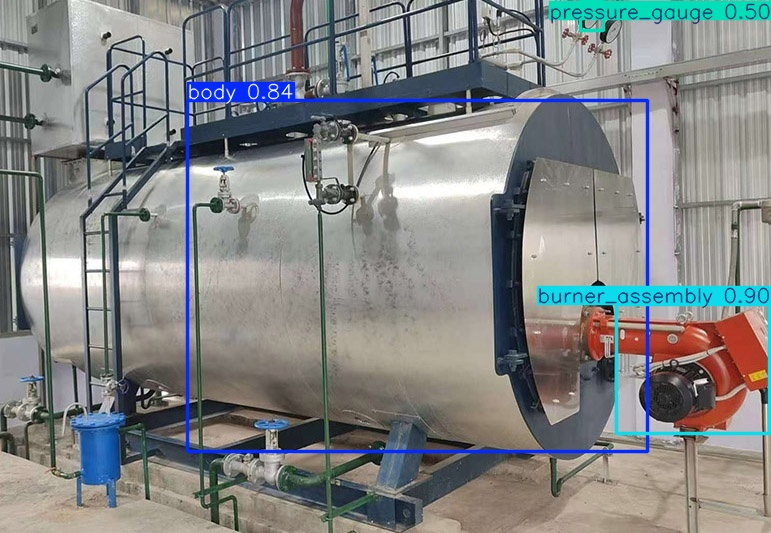


---------------------------------------------
Processing Image: testboiler.png
Boiler found.
Results saved to /content/drive/MyDrive/SDP_Team_21/multistage_output
Components identified in expanded ROI: 3
    • body (confidence: 86.84%)
    • burner_assembly (confidence: 85.90%)
    • gas_train (confidence: 49.76%)


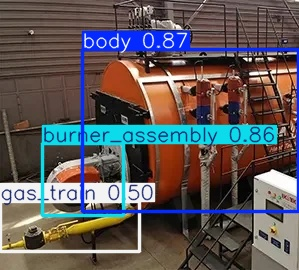


---------------------------------------------
Processing Image: testfueltank.jpg
No boiler detected in testfueltank.jpg. Skipping Phase 2.


In [12]:
!pip install -q ultralytics

import os
import glob
import cv2
from google.colab import drive
from ultralytics import YOLO
from PIL import Image

drive.mount('/content/drive')

base_team_dir = "/content/drive/MyDrive/SDP_Team_21"

phase1_weights = os.path.join(base_team_dir, "boiler_identification", "boiler_tuned_hparams", "weights", "best.pt")
phase2_weights = os.path.join(base_team_dir, "part_detection", "boiler_tuned_hparams", "weights", "best.pt")

macro_model = YOLO(phase1_weights)
component_model = YOLO(phase2_weights)

test_images_folder = os.path.join(base_team_dir, "test_images")
candidate_images = glob.glob(os.path.join(test_images_folder, "*.*"))

if len(candidate_images) == 0:
    print(f"No test images found in {test_images_folder}.")
else:
    print(f"Found {len(candidate_images)} test image(s) in Drive.")

    for img_path in candidate_images:
        image_name = os.path.basename(img_path)
        original_image = cv2.imread(img_path)

        if original_image is None:
            print(f"\nCould not read image file: {image_name}. Skipping.")
            continue

        print('\n' + '-' * 45)
        print(f"Processing Image: {image_name}")

        p1_results = macro_model.predict(source=img_path, conf=0.40, device='cpu', verbose=False)
        boxes = p1_results[0].boxes

        if len(boxes) == 0:
            print(f"No boiler detected in {image_name}. Skipping Phase 2.")
            continue

        print("Boiler found.")

        best_box = boxes[0].xyxy[0].cpu().numpy()
        xmin, ymin, xmax, ymax = map(int, best_box)

        img_h, img_w, _ = original_image.shape
        box_height = ymax - ymin
        box_width = xmax - xmin

        padded_ymin = max(0, ymin - int(box_height * 0.40))
        padded_xmin = max(0, xmin - int(box_width * 0.15))
        padded_xmax = min(img_w, xmax + int(box_width * 0.15))
        padded_ymax = min(img_h, ymax + int(box_height * 0.15))

        roi_crop = original_image[padded_ymin:padded_ymax, padded_xmin:padded_xmax]
        temp_crop_path = "temp_boiler_roi.jpg"
        cv2.imwrite(temp_crop_path, roi_crop)

        p2_results = component_model.predict(
            source=temp_crop_path,
            conf=0.40,
            iou=0.40,
            device='cpu',
            save=True,
            project=base_team_dir,
            name="multistage_output",
            exist_ok=True,
            verbose=False
        )

        p2_boxes = p2_results[0].boxes
        print(f"Components identified in expanded ROI: {len(p2_boxes)}")
        for box in p2_boxes:
            cls_id = int(box.cls[0].item())
            label = component_model.names[cls_id]
            conf_score = float(box.conf[0].item())
            print(f"    • {label} (confidence: {conf_score:.2%})")

        saved_file_name = os.path.basename(p2_results[0].path)
        final_output_path = os.path.join(p2_results[0].save_dir, saved_file_name)

        if os.path.exists(final_output_path):
            display(Image.open(final_output_path))